##  1 — Imports and settings

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, precision_recall_curve)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

SEED = 42
DATA = "../data/raw/bank_churn.csv"          # notebooks/ is one level below the repo root
OUT  = "../data/processed/scored_customers.csv"
pd.set_option("display.width", 140)

# 2 — Load the data and look at the target

In [3]:
raw = pd.read_csv(DATA)
print("shape:", raw.shape)
print("missing values per column:\n", raw.isna().sum()[raw.isna().sum() > 0])
assert raw["CustomerId"].is_unique, "Duplicate CustomerId found: investigate before modeling"
churn_rate = raw["Exited"].mean()
print(f"churn rate: {churn_rate:.3f}")

shape: (10000, 14)
missing values per column:
 Series([], dtype: int64)
churn rate: 0.204


# 3 — The baseline you must beat

In [4]:
majority_accuracy = 1 - churn_rate
print(f"'Nobody churns' accuracy: {majority_accuracy:.3f}  (and it catches 0 churners)")

'Nobody churns' accuracy: 0.796  (and it catches 0 churners)


# 4 — Separate the target and drop identifier columns

In [5]:
y   = raw["Exited"].astype(int)
ids = raw["CustomerId"]
df  = raw.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
print(df.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


# 5 — Feature engineering (row-wise only)

In [6]:
df["HasZeroBalance"]      = (df["Balance"] == 0).astype(int)
df["BalanceToSalary"]     = df["Balance"] / df["EstimatedSalary"].replace(0, np.nan)
df["AgeBand"]             = pd.cut(df["Age"], [0, 29, 39, 49, 59, 120],
                                   labels=["<30", "30-39", "40-49", "50-59", "60+"]).astype(str)
df["ProductsGroup"]       = df["NumOfProducts"].clip(upper=3).astype(str).replace({"3": "3+"})
df["TenureYoungAccount"]  = (df["Tenure"] <= 1).astype(int)
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,HasZeroBalance,BalanceToSalary,AgeBand,ProductsGroup,TenureYoungAccount
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.000000,40-49,1,0
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0.744677,40-49,1,1
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,0,1.401375,40-49,3+,0
3,699,France,Female,39,1,0.00,2,0,0,93826.63,1,0.000000,30-39,2,1
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1.587055,40-49,1,0


# 6 — Split the data (the test set is locked away)

In [7]:
X_tr, X_te, y_tr, y_te = train_test_split(df, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_tr.shape, "| test:", X_te.shape)
print(f"churn rate  train: {y_tr.mean():.3f} | test: {y_te.mean():.3f}")

train: (8000, 15) | test: (2000, 15)
churn rate  train: 0.204 | test: 0.203


# 7 — Build the preprocessing and the four models

In [8]:
def build_models(num, cat):
    def prep(scale):
        steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
        return ColumnTransformer([("num", Pipeline(steps), num),
                                  ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return {
        "Baseline (majority)": Pipeline([("p", prep(False)), ("m", DummyClassifier(strategy="prior"))]),
        "LogReg": Pipeline([("p", prep(True)),
                            ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "RandomForest": Pipeline([("p", prep(False)),
                                  ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                        class_weight="balanced", n_jobs=-1, random_state=SEED))]),
        "HistGB": Pipeline([("p", prep(False)),
                            ("m", HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05,
                                  max_iter=300, class_weight="balanced", random_state=SEED))]),
    }

num = X_tr.select_dtypes("number").columns.tolist()
cat = X_tr.select_dtypes(exclude="number").columns.tolist()
models = build_models(num, cat)
print("numeric:", num); print("categorical:", cat)

numeric: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'HasZeroBalance', 'BalanceToSalary', 'TenureYoungAccount']
categorical: ['Geography', 'Gender', 'AgeBand', 'ProductsGroup']


# 8 — Compare models with cross-validation (training data only)

In [9]:
import warnings; warnings.filterwarnings("ignore", message=".*ill-defined.*")
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, pipe in models.items():
    s = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=["roc_auc", "average_precision", "recall", "precision"])
    rows.append({"model": name,
                 **{k: round(s[f"test_{k}"].mean(), 3) for k in ["roc_auc", "average_precision", "recall", "precision"]},
                 "pr_auc_std": round(s["test_average_precision"].std(), 3)})
cmp_df = pd.DataFrame(rows).set_index("model")
cmp_df

,roc_auc,average_precision,recall,precision,pr_auc_std
model,,,,,
Baseline (majority),0.500,0.204,0.000,0.000,0.000
LogReg,0.843,0.649,0.746,0.466,0.020
RandomForest,0.858,0.679,0.707,0.518,0.022
HistGB,0.863,0.699,0.730,0.521,0.024


# 9 — Pick the best model and choose the threshold (still no test data)

Best model by CV PR-AUC: HistGB
Threshold chosen on training out-of-fold predictions: 0.615


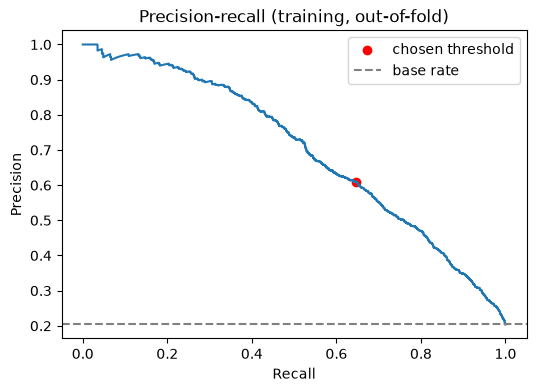

In [10]:
best_name = cmp_df.drop("Baseline (majority)")["average_precision"].idxmax()
best = models[best_name]
print("Best model by CV PR-AUC:", best_name)

oof = cross_val_predict(best, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
threshold = float(thr[f1s.argmax()])
print(f"Threshold chosen on training out-of-fold predictions: {threshold:.3f}")

plt.figure(figsize=(6, 4)); plt.plot(rec, prec); plt.scatter(rec[:-1][f1s.argmax()], prec[:-1][f1s.argmax()], c="red", label="chosen threshold")
plt.axhline(y_tr.mean(), ls="--", c="grey", label="base rate"); plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-recall (training, out-of-fold)"); plt.legend(); plt.show()

# 10 — Final fit and the one holdout evaluation

In [11]:
best.fit(X_tr, y_tr)
p    = best.predict_proba(X_te)[:, 1]
pred = (p >= threshold).astype(int)

print(f"ROC-AUC  {roc_auc_score(y_te, p):.3f}")
print(f"PR-AUC   {average_precision_score(y_te, p):.3f}   (base rate = {y_te.mean():.3f})")
print(f"Precision {precision_score(y_te, pred):.3f} | Recall {recall_score(y_te, pred):.3f} | F1 {f1_score(y_te, pred):.3f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:\n", confusion_matrix(y_te, pred))

ROC-AUC  0.866
PR-AUC   0.714   (base rate = 0.203)
Precision 0.600 | Recall 0.649 | F1 0.623
Confusion matrix [[TN, FP], [FN, TP]]:
 [[1417  176]
 [ 143  264]]


# 11 — Which features matter? (permutation importance)

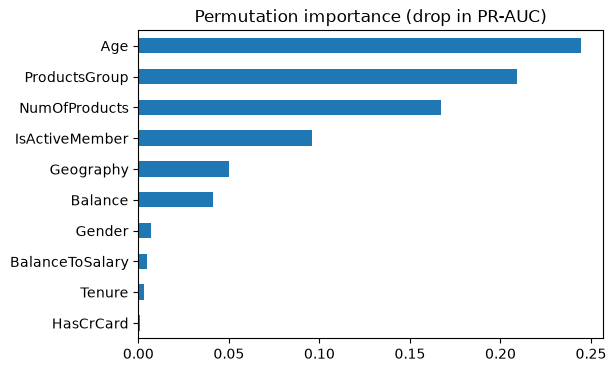

In [12]:
pi  = permutation_importance(best, X_te, y_te, scoring="average_precision", n_repeats=10, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
imp.tail(10).plot(kind="barh", figsize=(6, 4), title="Permutation importance (drop in PR-AUC)"); plt.show()

# 12 — Lift and gain: the view a retention manager uses

,customers,churners,cum_gain,lift
decile,,,,
1,200,166,0.408,4.079
2,200,88,0.624,2.162
3,200,50,0.747,1.229
4,200,36,0.835,0.885
5,200,23,0.892,0.565
6,200,16,0.931,0.393
7,200,9,0.953,0.221
8,200,10,0.978,0.246
9,200,5,0.990,0.123


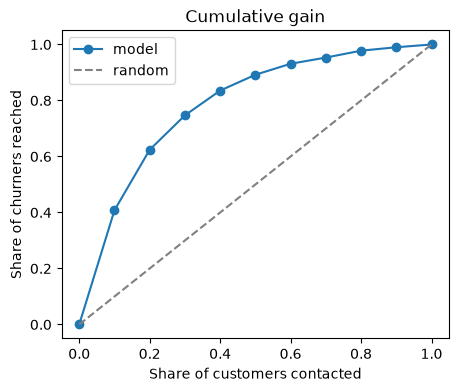

In [13]:
t = pd.DataFrame({"p": p, "y": y_te.values}).sort_values("p", ascending=False).reset_index(drop=True)
t["decile"] = pd.qcut(t.index, 10, labels=range(1, 11))
g = t.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"))
g["cum_gain"] = (g["churners"] / g["churners"].sum()).cumsum()
g["lift"]     = (g["churners"] / g["customers"]) / t["y"].mean()
display(g.round(3))

x = np.arange(0, 11) / 10; plt.figure(figsize=(5, 4))
plt.plot(x, np.r_[0, g["cum_gain"].values], marker="o", label="model"); plt.plot(x, x, "--", c="grey", label="random")
plt.xlabel("Share of customers contacted"); plt.ylabel("Share of churners reached"); plt.title("Cumulative gain"); plt.legend(); plt.show()

# 13 — Calibration: are the probabilities real probabilities?

,mean_predicted,observed_rate
0,0.030,0.020
1,0.069,0.025
2,0.117,0.050
3,0.170,0.045
4,0.234,0.080
5,0.321,0.115
6,0.425,0.180
7,0.571,0.250
8,0.737,0.440
9,0.929,0.830


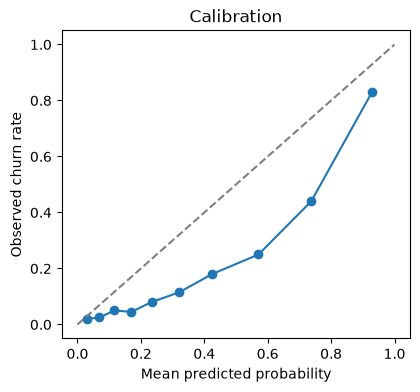

In [14]:
frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
display(pd.DataFrame({"mean_predicted": mean_pred, "observed_rate": frac_pos}).round(3))
plt.figure(figsize=(4.5, 4)); plt.plot(mean_pred, frac_pos, marker="o"); plt.plot([0, 1], [0, 1], "--", c="grey")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed churn rate"); plt.title("Calibration"); plt.show()

# 14 — A cost-based threshold (with assumptions clearly labeled)

In [15]:
def net_benefit(th, probs, y_true, value_saved, cost_contact, save_rate):
    contact = probs >= th
    return (contact & (y_true == 1)).sum() * save_rate * value_saved - contact.sum() * cost_contact

ths = np.linspace(0.05, 0.95, 91)
rows = []
for save_rate in [0.10, 0.25, 0.40]:
    for cost in [15, 25, 40]:
        value = 400                                                        # assumed value of a saved customer
        nb_train = [net_benefit(t_, oof, y_tr.values, value, cost, save_rate) for t_ in ths]
        th_best = ths[int(np.argmax(nb_train))]                           # chosen on training OOF only
        nb_test = net_benefit(th_best, p, y_te.values, value, cost, save_rate) / len(y_te) * 1000
        rows.append({"save_rate": save_rate, "contact_cost": cost, "chosen_threshold": round(th_best, 2),
                     "net_benefit_per_1000_customers (holdout, ASSUMPTION-BASED)": round(nb_test)})
display(pd.DataFrame(rows))

,save_rate,contact_cost,chosen_threshold,"net_benefit_per_1000_customers (holdout, ASSUMPTION-BASED)"
0,0.10,15,0.74,2015
1,0.10,25,0.85,875
2,0.10,40,0.95,-100
3,0.25,15,0.41,11022
4,0.25,25,0.57,8125
5,0.25,40,0.74,4670
6,0.40,15,0.23,21488
7,0.40,25,0.41,17278
8,0.40,40,0.57,13000


# 15 — Export scored customers for Power BI

In [16]:
scored = pd.concat([
    X_tr.assign(churn_probability=oof, actual_churn=y_tr, split="train (out-of-fold)"),
    X_te.assign(churn_probability=p,   actual_churn=y_te, split="test (holdout)")])
scored["CustomerId"]      = ids.loc[scored.index]
scored["predicted_churn"] = (scored["churn_probability"] >= threshold).astype(int)
scored["risk_band"]       = pd.cut(scored["churn_probability"], [-.01, .3, .6, 1.0], labels=["Low", "Medium", "High"])
scored.sort_index().to_csv(OUT, index=False)
print("Exported", len(scored), "customers to", OUT)

Exported 10000 customers to ../data/processed/scored_customers.csv


# 15b — Export the extra tables Power BI needs

In [17]:
import os
os.makedirs("../data/processed", exist_ok=True)
P = "../data/processed/"

lift = g.reset_index()
lift["decile"] = lift["decile"].astype(int)
lift["random_gain"] = lift["decile"] / 10                      # what random targeting would reach
lift.to_csv(P + "lift_table.csv", index=False)

cmp_df.reset_index().to_csv(P + "model_comparison.csv", index=False)

(imp.sort_values(ascending=False).rename("importance").reset_index()
    .rename(columns={"index": "feature"}).to_csv(P + "permutation_importance.csv", index=False))

metrics = pd.DataFrame({
    "metric": ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1", "Threshold", "Base rate (test)", "Baseline accuracy (nobody churns)"],
    "value":  [roc_auc_score(y_te, p), average_precision_score(y_te, p), precision_score(y_te, pred),
               recall_score(y_te, pred), f1_score(y_te, pred), threshold, y_te.mean(), majority_accuracy]})
metrics["best_model"] = best_name
metrics.round(4).to_csv(P + "holdout_metrics.csv", index=False)
print(metrics.round(3))

                              metric  value best_model
0                            ROC-AUC  0.866     HistGB
1                             PR-AUC  0.714     HistGB
2                          Precision  0.600     HistGB
3                             Recall  0.649     HistGB
4                                 F1  0.623     HistGB
5                          Threshold  0.615     HistGB
6                   Base rate (test)  0.204     HistGB
7  Baseline accuracy (nobody churns)  0.796     HistGB
